# 09 — Traitement du signal : bruit, filtres et FFT

Un capteur ne délivre jamais une tension parfaite : le signal utile est
toujours mélangé à du **bruit**. En électronique, on combat ce bruit avec des
filtres, puis on analyse le résultat dans le domaine fréquentiel grâce à la
**transformée de Fourier**. Ce notebook construit un signal synthétique
proche d'une mesure réelle, le filtre de deux façons et vérifie le gain.

**Objectifs du notebook**

- générer un signal sinusoïdal échantillonné et un bruit gaussien ;
- quantifier la qualité d'un signal avec le rapport signal/bruit (SNR) ;
- appliquer une moyenne glissante puis un filtre passe-bas de Butterworth ;
- calculer et interpréter un spectre avec la FFT ;
- mesurer l'amélioration apportée par un filtre, en dB et en RMS.

**Prérequis** : tableaux NumPy, fonctions et tracés Matplotlib (notebooks
06 et 07). Aucune connaissance de scipy n'est nécessaire.


## Utilisation en ligne (Google Colab)

Cette cellule ne fait rien sur votre ordinateur. Dans Google Colab, elle
clone le dépôt public (données comprises) et place le notebook à sa racine,
afin que les chemins `data/...` fonctionnent. Exécutez-la en premier.


In [1]:
import os  # manipulation des chemins et du dossier courant
import subprocess  # lance la commande git clone
import sys  # permet de détecter l'environnement Colab

DEPOT = "https://github.com/VladdKid/python-electronique-ia.git"  # adresse publique du cours
DOSSIER = "python-electronique-ia"  # dossier local créé par le clone

if "google.colab" in sys.modules and not os.path.isdir("data"):  # uniquement dans Colab, si les données manquent
    if not os.path.isdir(DOSSIER):  # évite de cloner deux fois le dépôt
        subprocess.run(["git", "clone", "--depth", "1", DEPOT, DOSSIER], check=True)  # télécharge le cours
    os.chdir(DOSSIER)  # se place à la racine du dépôt cloné
    print(f"Dépôt prêt : {os.getcwd()}")  # confirme le dossier de travail


## 1. Fabriquer un signal échantillonné

Un convertisseur analogique-numérique prélève le signal à la fréquence
d'échantillonnage `fs`. Le théorème de Shannon impose `fs > 2 × f_max` :
avec `fs = 1000 Hz`, on peut observer sans erreur jusqu'à 500 Hz. Le signal
utile est un sinus à 50 Hz, comme le bruit de réseau, auquel on ajoute un
bruit blanc gaussien d'écart-type 0,35 V.


In [2]:
import numpy as np  # tableaux et fonctions mathématiques (sinus, moyenne, racine)
import matplotlib.pyplot as plt  # tracés de courbes
from scipy.signal import butter, sosfilt  # filtre passe-bas de Butterworth et son application


On construit maintenant le signal de test. La graine du générateur aléatoire
est fixée pour que tous les étudiants obtiennent exactement les mêmes
valeurs, ce qui facilite la comparaison des résultats.


In [3]:
fs = 1000.0  # fréquence d'échantillonnage : 1000 échantillons par seconde
duree = 1.0  # durée de l'enregistrement : 1 seconde
t = np.arange(0.0, duree, 1.0 / fs)  # vecteur temps : 1000 instants régulièrement espacés
f_signal = 50.0  # fréquence du signal utile : 50 Hz (réseau électrique)
amplitude = 1.0  # amplitude du signal utile : 1 V
sigma = 0.35  # écart-type du bruit : plus il est grand, plus le signal est noyé
rng = np.random.default_rng(42)  # générateur aléatoire à graine fixe : résultat reproductible
signal_propre = amplitude * np.sin(2 * np.pi * f_signal * t)  # sinusoïde idéale à 50 Hz
bruit = rng.normal(0.0, sigma, t.size)  # bruit blanc gaussien de moyenne nulle
signal_bruite = signal_propre + bruit  # signal tel qu'il sortirait d'un capteur réel
print(f"{t.size} échantillons sur {duree} s, soit fs = {fs:.0f} Hz")  # vérifie la base de temps


1000 échantillons sur 1.0 s, soit fs = 1000 Hz


## 2. Rapport signal/bruit (SNR)

Le SNR compare la puissance moyenne du signal utile à celle du bruit. On
l'exprime en décibels : `SNR_dB = 10 × log10(P_signal / P_bruit)`. Un SNR de
6 dB signifie que le signal est à peine quatre fois plus puissant que le
bruit : la sinusoïde reste visible, mais épaisse. Chaque gain de 3 dB
correspond à un doublement du rapport de puissances.


In [4]:
def snr_db(signal, perturbation):  # définit une fonction réutilisable de calcul du SNR
    return 10 * np.log10(np.mean(signal ** 2) / np.mean(perturbation ** 2))  # 10 log10 du rapport des puissances moyennes


La fonction `snr_db` servira à chaque étape du notebook. On calcule d'abord
les deux puissances séparément, puis le rapport : c'est la référence à
battre pour juger les filtres.


In [5]:
puissance_signal = np.mean(signal_propre ** 2)  # puissance moyenne du signal utile (A²/2 pour un sinus)
puissance_bruit = np.mean(bruit ** 2)  # puissance moyenne du bruit (proche de sigma²)
snr_avant = snr_db(signal_propre, bruit)  # SNR du signal bruité, en décibels
print(f"Puissance signal : {puissance_signal:.3f} | Puissance bruit : {puissance_bruit:.3f}")  # affiche les deux puissances
print(f"SNR avant filtrage : {snr_avant:.2f} dB")  # affiche le SNR initial


Puissance signal : 0.500 | Puissance bruit : 0.120
SNR avant filtrage : 6.20 dB


## 3. Filtre moyenne glissante

La moyenne glissante remplace chaque échantillon par la moyenne des `N`
derniers. C'est un filtre passe-bas très simple, réalisé par une convolution
avec un noyau de `N` coefficients valant `1/N`. Il réduit le bruit d'un
facteur proche de `√N`, mais il déforme les bords du signal (effets de bord)
et atténue les composantes rapides : avec `N = 5`, la fenêtre dure 5 ms,
ce qui reste court devant la période de 20 ms du 50 Hz.


In [6]:
N = 5  # taille de la fenêtre de moyenne : 5 échantillons, soit 5 ms
noyau = np.ones(N) / N  # noyau de convolution : N coefficients égaux à 1/N
signal_moyenne = np.convolve(signal_bruite, noyau, mode="same")  # moyenne glissante, même longueur que l'entrée
erreur_moyenne = signal_moyenne - signal_propre  # écart entre signal filtré et signal idéal
rms_moyenne = np.sqrt(np.mean(erreur_moyenne ** 2))  # erreur quadratique moyenne (RMS) du filtrage
snr_moyenne = snr_db(signal_propre, erreur_moyenne)  # SNR effectif après moyennage
print(f"Moyenne glissante N={N} : erreur RMS = {rms_moyenne:.3f} V, SNR = {snr_moyenne:.2f} dB")  # affiche le résultat


Moyenne glissante N=5 : erreur RMS = 0.178 V, SNR = 11.99 dB


## 4. Filtre passe-bas de Butterworth

Un filtre de Butterworth est un filtre analogique idéal approché : sa
réponse est maximale en basse fréquence et décroît régulièrement après la
fréquence de coupure. `scipy` travaille avec une fréquence **normalisée par
Nyquist** : `fc / (fs / 2)`. Ici 120 / 500 = 0,24. L'ordre 4 donne une pente
de 24 dB par octave, largement suffisante pour laisser passer le 50 Hz tout
en coupant le bruit haute fréquence.


In [7]:
fc = 120.0  # fréquence de coupure : 120 Hz, au-dessus du signal utile de 50 Hz
ordre = 4  # ordre du filtre : pente d'atténuation de 24 dB par octave
frequence_nyquist = fs / 2  # fréquence de Nyquist : 500 Hz, plus haute fréquence représentable
sos = butter(ordre, fc / frequence_nyquist, btype="low", output="sos")  # coefficients du filtre, coupure normalisée
signal_filtre = sosfilt(sos, signal_bruite)  # applique le filtre échantillon par échantillon
print(f"Coupure normalisée : {fc / frequence_nyquist:.2f} (0 = continu, 1 = Nyquist)")  # affiche la fréquence normalisée


Coupure normalisée : 0.24 (0 = continu, 1 = Nyquist)


## 5. Transformée de Fourier (FFT)

La FFT décompose le signal en sinusoïdes : elle transforme 1000 valeurs
temporelles en 501 amplitudes fréquentielles (de 0 à 500 Hz). `rfft` exploite
le fait que le signal est réel pour ne calculer que les fréquences positives.
Pour retrouver l'amplitude crête d'un sinus, on multiplie par 2 (l'énergie
est partagée entre fréquences positives et négatives) et on divise par `n` ;
la composante continue à 0 Hz ne doit pas être doublée.


In [8]:
n = t.size  # nombre d'échantillons du signal
X_bruite = np.fft.rfft(signal_bruite)  # transformée de Fourier réelle : spectre des fréquences positives
frequences = np.fft.rfftfreq(n, d=1.0 / fs)  # fréquences correspondantes, de 0 à fs/2 = 500 Hz
amplitude_bruite = 2 * np.abs(X_bruite) / n  # amplitude crête : facteur 2 car rfft ne garde que la moitié du spectre
amplitude_bruite[0] = amplitude_bruite[0] / 2  # la composante continue (0 Hz) ne doit pas être doublée
X_filtre = np.fft.rfft(signal_filtre)  # spectre du signal après filtrage
amplitude_filtre = 2 * np.abs(X_filtre) / n  # même normalisation pour comparer les deux spectres
amplitude_filtre[0] = amplitude_filtre[0] / 2  # correction de la composante continue
indice_pic = np.argmax(amplitude_bruite)  # indice du pic le plus élevé du spectre bruité
frequence_dominante = frequences[indice_pic]  # fréquence associée à ce pic
print(f"Fréquence dominante : {frequence_dominante:.1f} Hz")  # doit retrouver les 50 Hz du signal
print(f"Amplitude à 50 Hz : avant {amplitude_bruite[indice_pic]:.3f} V, après {amplitude_filtre[indice_pic]:.3f} V")  # compare le fondamental


Fréquence dominante : 50.0 Hz
Amplitude à 50 Hz : avant 0.992 V, après 0.989 V


## 6. Visualiser les quatre signaux

La figure superpose les domaines temporel et fréquentiel, avant et après
filtrage. En haut, le signal filtré doit suivre la sinusoïde idéale malgré
un léger retard. En bas, le pic à 50 Hz doit rester à la même amplitude,
tandis que le plancher de bruit autour doit nettement baisser.


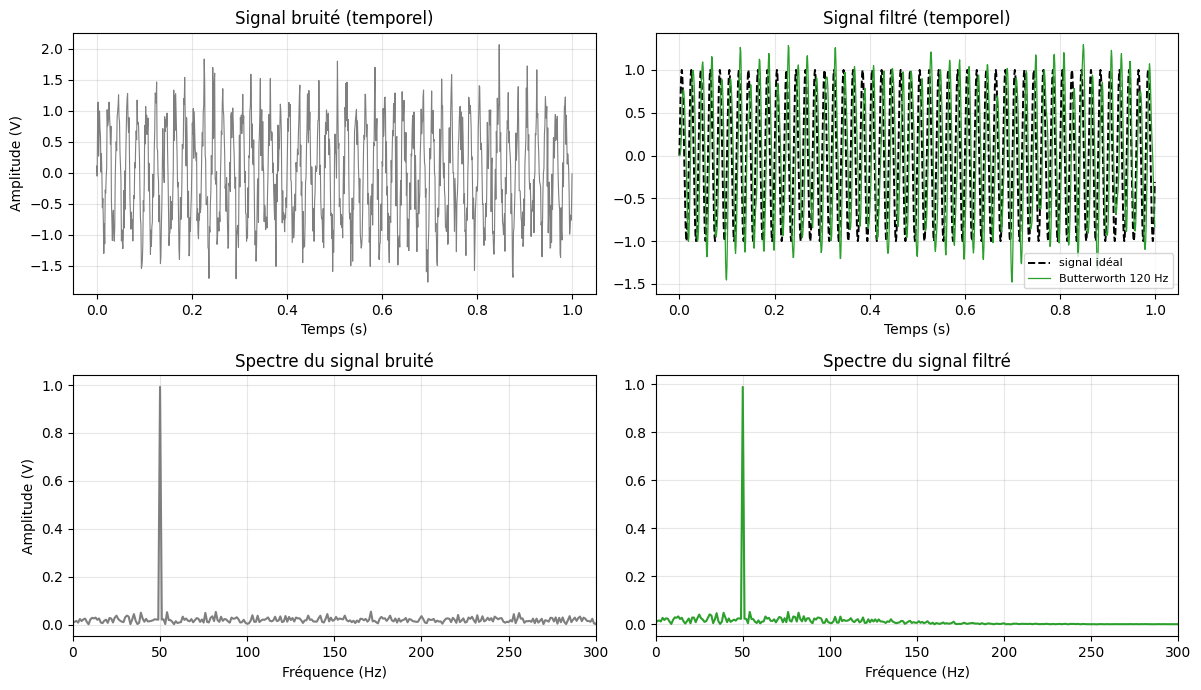

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="row")  # grille 2 × 2 : temps en haut, spectres en bas
axes[0, 0].plot(t, signal_bruite, color="tab:gray", lw=0.8)  # signal brut dans le domaine temporel
axes[0, 0].set(title="Signal bruité (temporel)", xlabel="Temps (s)", ylabel="Amplitude (V)")  # titre et axes
axes[0, 1].plot(t, signal_propre, color="black", ls="--", lw=1.4, label="signal idéal")  # référence sans bruit, tracée en premier
axes[0, 1].plot(t, signal_filtre, color="tab:green", lw=0.9, label="Butterworth 120 Hz")  # signal filtré par-dessus la référence
axes[0, 1].set(title="Signal filtré (temporel)", xlabel="Temps (s)")  # titre et axe horizontal partagé
axes[0, 1].legend(fontsize=8)  # légende des deux courbes
axes[1, 0].plot(frequences, amplitude_bruite, color="tab:gray")  # spectre d'amplitude avant filtrage
axes[1, 0].set(title="Spectre du signal bruité", xlabel="Fréquence (Hz)", ylabel="Amplitude (V)", xlim=(0, 300))  # zoom sur 0-300 Hz
axes[1, 1].plot(frequences, amplitude_filtre, color="tab:green")  # spectre d'amplitude après filtrage
axes[1, 1].set(title="Spectre du signal filtré", xlabel="Fréquence (Hz)", xlim=(0, 300))  # même échelle horizontale
for ax in axes.flat:  # parcourt les quatre sous-graphiques
    ax.grid(alpha=0.3)  # ajoute une grille discrète à chacun
plt.tight_layout()  # ajuste les marges pour éviter les chevauchements
plt.show()  # affiche la figure dans le notebook


## 7. Mesurer le gain du filtrage

Un filtre introduit un **retard** : la sinusoïde filtrée est décalée de
quelques millisecondes. Si l'on compare directement le signal filtré au
signal idéal, ce décalage se traduit par une erreur énorme et un SNR
trompeur. On estime le retard par corrélation croisée, on le compense, puis
on calcule l'erreur résiduelle. C'est le bruit restant qui nous intéresse.


In [10]:
retard = np.argmax(np.correlate(signal_filtre, signal_propre, mode="full")) - (n - 1)  # retard du filtre, en échantillons
signal_filtre_aligne = np.roll(signal_filtre, -retard)  # recale le signal filtré pour compenser ce retard
erreur_filtre = signal_filtre_aligne - signal_propre  # bruit résiduel après filtrage et recalage
rms_filtre = np.sqrt(np.mean(erreur_filtre ** 2))  # erreur quadratique moyenne du filtre
snr_apres = snr_db(signal_propre, erreur_filtre)  # SNR effectif après filtrage
rms_bruite = np.sqrt(np.mean(bruit ** 2))  # RMS du bruit avant filtrage, pour comparaison
print(f"Retard du filtre : {retard} échantillons = {1000 * retard / fs:.1f} ms")  # affiche le retard en millisecondes
print(f"RMS bruit : {rms_bruite:.3f} V -> {rms_filtre:.3f} V | SNR : {snr_avant:.2f} -> {snr_apres:.2f} dB")  # bilan du filtrage


Retard du filtre : 3 échantillons = 3.0 ms
RMS bruit : 0.346 V -> 0.205 V | SNR : 6.20 -> 10.75 dB


Le filtre de Butterworth conserve le 50 Hz (atténuation inférieure à 1 %)
et améliore le SNR d'environ 4,5 dB. La moyenne glissante `N = 5` fait mieux
sur le bruit, mais elle décale et déforme légèrement le signal. Une fenêtre
trop longue, `N = 101` par exemple, agirait comme un filtre à 10 Hz : elle
supprimerait purement et simplement le sinus de 50 Hz. Le choix du filtre
dépend donc de la bande utile, pas seulement du bruit à éliminer.


## 8. À vous de jouer

Complétez les cellules suivantes. Rechargez le signal bruité tel qu'il est
défini en section 1, puis testez d'autres réglages.


**Exercice 1** — Refaites le filtre de Butterworth avec une coupure à 60 Hz
au lieu de 120 Hz. Affichez l'amplitude du pic à 50 Hz et le SNR après
recalage. Le 50 Hz est-il atténué ? Que devient le bruit ?


In [11]:
# TODO : créez sos_60 = butter(4, 60 / (fs / 2), btype="low", output="sos")

# TODO : filtrez signal_bruite avec sosfilt et stockez le résultat

# TODO : calculez le spectre, affichez l'amplitude à 50 Hz

# TODO : estimez le retard, alignez, puis affichez le SNR après filtrage


**Exercice 2** — Remplacez la moyenne glissante par `N = 101`. Affichez le
RMS d'erreur et le SNR effectif, puis commentez : le filtre est-il encore
adapté à un signal de 50 Hz ?


In [12]:
# TODO : définissez N = 101 et le noyau np.ones(N) / N

# TODO : convoluez signal_bruite avec ce noyau (mode="same")

# TODO : calculez l'erreur, le RMS et le SNR avec snr_db

# TODO : concluez dans un commentaire : que reste-t-il du signal utile ?


**Exercice 3** — Calculez un rapport de distorsion simplifié : énergie
présente hors de la bande 45-55 Hz divisée par l'énergie du pic à 50 Hz,
avant puis après filtrage. Ce rapport diminue si le filtre nettoie le bruit.


In [13]:
# TODO : construisez le masque (frequences > 45) & (frequences < 55)

# TODO : calculez le rapport des sommes des carrés d'amplitudes hors bande / dans la bande

# TODO : refaites le calcul avec amplitude_filtre et comparez les deux valeurs


## 9. À retenir

- Un signal échantillonné à `fs` ne contient que des fréquences jusqu'à
  `fs/2` (théorème de Shannon) ; la FFT utilise cette fréquence de Nyquist.
- Le SNR en dB vaut `10 × log10(P_signal / P_bruit)` ; il augmente quand le
  bruit diminue.
- Une moyenne glissante est un filtre passe-bas simple, avec des effets de
  bord et une atténuation qui dépend de `N`.
- `butter` attend une fréquence normalisée par Nyquist ; `sosfilt` applique
  le filtre sans dérive numérique.
- La FFT donne le spectre d'amplitude : un pic à 50 Hz signe le signal utile,
  le reste est du bruit.
- Un filtre introduit un retard : il faut l'aligner avant de comparer au
  signal de référence.

**Notebook suivant** : `10 — Apprentissage automatique avec scikit-learn`.
Les indicateurs calculés ici (RMS, énergie par bande, SNR) deviendront des
**variables d'entrée** pour un modèle de classification de défauts.
